# House Prices: k-means, DBSCAN, PCA

## 1. Loading and preparing the dataset

In [67]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from scipy.spatial.distance import pdist, squareform


pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [3]:
TRAIN_PATH = 'house-prices-advanced-regression-techniques/train.csv'
df = pd.read_csv(TRAIN_PATH, na_values=["NA"], keep_default_na=True)

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
numeric_cols_all = df.select_dtypes(include=[np.number]).columns.tolist()

EXCLUDE_ALWAYS = ['Id', 'SalePrice', 'MoSold', 'YrSold']
candidate_cols = [c for c in numeric_cols_all if c not in EXCLUDE_ALWAYS]

print(f"Numeric candidate features for clustering: {len(candidate_cols)}")
print(candidate_cols)

Numeric candidate features for clustering: 34
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


In [5]:
variance_check = df[candidate_cols].var(numeric_only=True).sort_values()
near_constant = variance_check[variance_check < 1e-6].index.tolist()
print(f"Features with practically zero variance (excluded): {near_constant}")

CLUSTER_FEATURES = [c for c in candidate_cols if c not in near_constant]
print(f"\nFinal list of features for clustering ({len(CLUSTER_FEATURES)}):")
print(CLUSTER_FEATURES)

Features with practically zero variance (excluded): []

Final list of features for clustering (34):
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


## 2. Exploratory data analysis

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [7]:
missing = df[CLUSTER_FEATURES].isna().sum()[lambda s: s > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({
    'n_missing': missing,
    'pct_missing': missing_pct,
})
print(f"Features with missing values among the selected ones: {len(missing_table)}")
missing_table

Features with missing values among the selected ones: 3


,n_missing,pct_missing
LotFrontage,259,17.74
GarageYrBlt,81,5.55
MasVnrArea,8,0.55


In [8]:
ZERO_MEANS_ABSENCE = [c for c in ['GarageYrBlt', 'MasVnrArea'] if c in CLUSTER_FEATURES]

X = df[CLUSTER_FEATURES].copy()

for col in ZERO_MEANS_ABSENCE:
    X[col] = X[col].fillna(0)

remaining_missing = [c for c in CLUSTER_FEATURES if X[c].isna().any() and X[c].notna().any()]
if remaining_missing:
    imputer = SimpleImputer(strategy='median')
    X[remaining_missing] = imputer.fit_transform(X[remaining_missing])

print(f"Missing values in X after processing: {X.isna().sum().sum()}")
print(f"Dimensions of X: {X.shape}")

Missing values in X after processing: 0
Dimensions of X: (1460, 34)


## 3. Feature matrix X and target vector y

In [9]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1460.0,69.863699,22.027677,21.0,60.00,69.0,79.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1460.0,103.117123,180.731373,0.0,0.00,0.0,164.25,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0


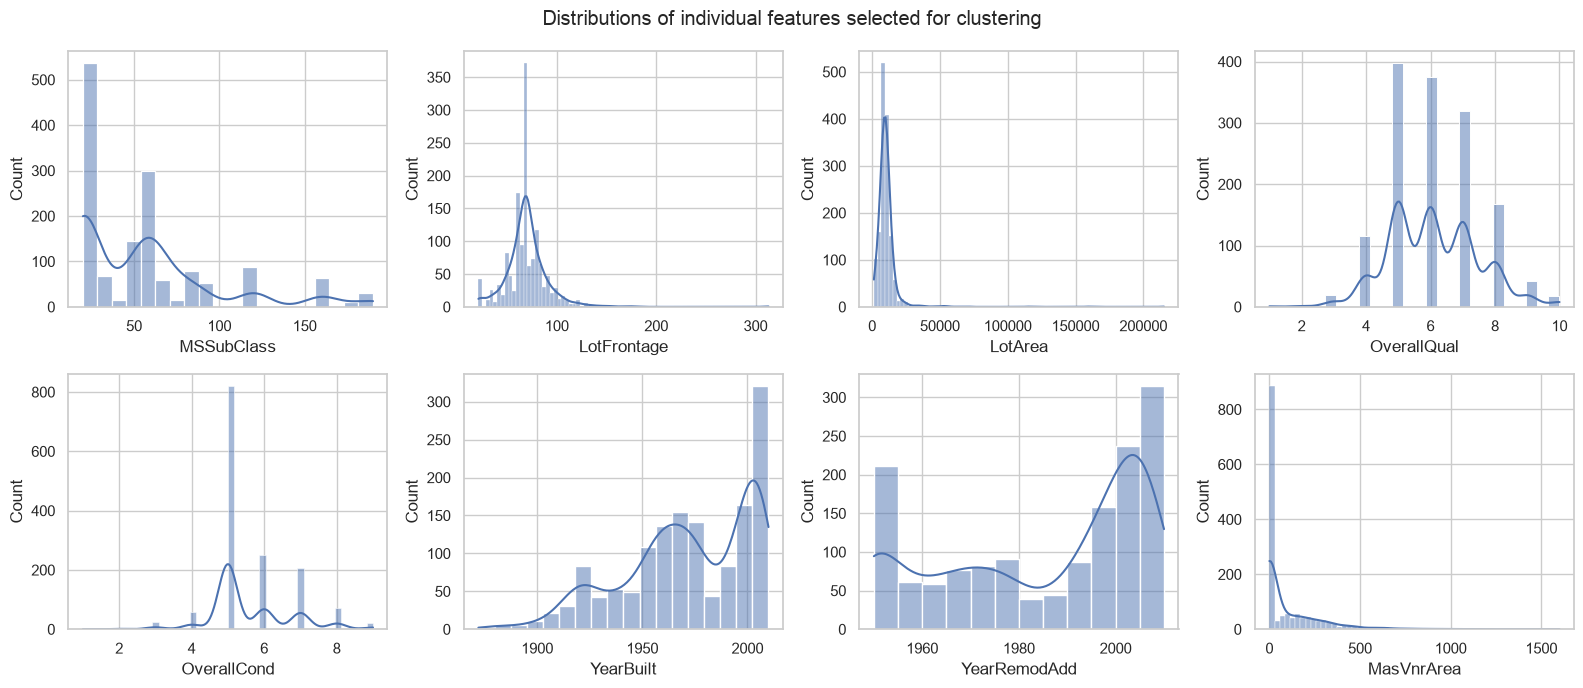

In [10]:
n_plot = min(8, len(CLUSTER_FEATURES))
fig, axes = plt.subplots(2, 4, figsize=(16,7))
axes = axes.flatten()
for ax, c in zip(axes, CLUSTER_FEATURES[:n_plot]):
    sns.histplot(X[c], kde=True, ax=ax)
for ax in axes[n_plot:]:
    ax.axis('off')
plt.suptitle('Distributions of individual features selected for clustering')
plt.tight_layout()
plt.show()

## 4. Scaling of numeric features

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=CLUSTER_FEATURES, index=X.index)

print("Statistics before scaling:")
display(X[CLUSTER_FEATURES[:6]].agg(['mean', 'std']).T)

print("\nStatistics after scaling:")
display(X_scaled_df[CLUSTER_FEATURES[:6]].agg(['mean', 'std']).T)

Statistics before scaling:


,mean,std
MSSubClass,56.897260,42.300571
LotFrontage,69.863699,22.027677
LotArea,10516.828082,9981.264932
OverallQual,6.099315,1.382997
OverallCond,5.575342,1.112799
YearBuilt,1971.267808,30.202904



Statistics after scaling:


,mean,std
MSSubClass,-8.455945e-17,1.000343
LotFrontage,2.798370e-16,1.000343
LotArea,-5.840077e-17,1.000343
OverallQual,1.387018e-16,1.000343
OverallCond,3.540547e-16,1.000343
YearBuilt,1.046347e-15,1.000343


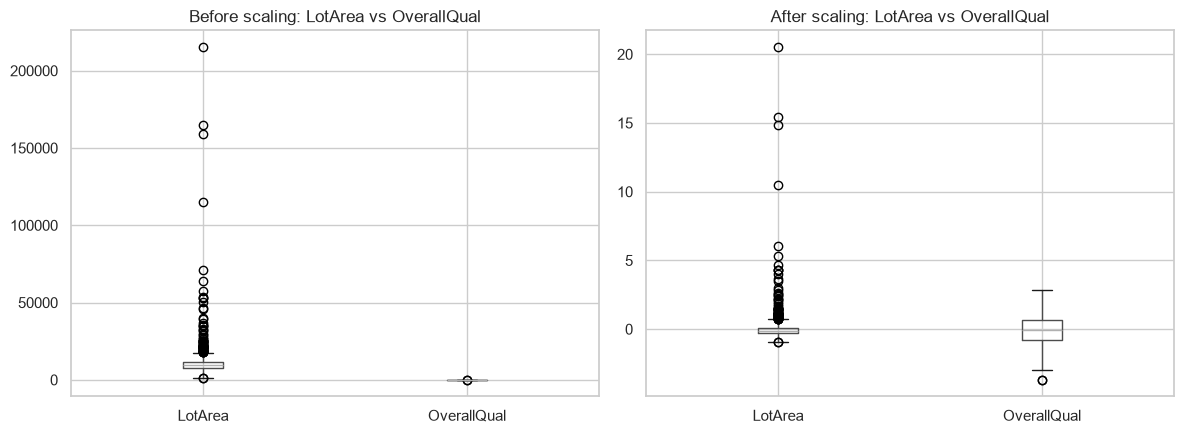

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
X[['LotArea', 'OverallQual']].boxplot(ax=axes[0])
axes[0].set_title('Before scaling: LotArea vs OverallQual')
X_scaled_df[['LotArea', 'OverallQual']].boxplot(ax=axes[1])
axes[1].set_title('After scaling: LotArea vs OverallQual')
plt.tight_layout()
plt.show()

## 5-6. k-means

In [13]:
k_values = list(range(2, 11))

kmeans_results = []
kmeans_models = {}
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    kmeans_models[k] = model
    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    kmeans_results.append({'k': k, 'inertia': model.inertia_, 'silhouette': sil, 'davies_bouldin': db, 'calinski_harabasz': ch})

kmeans_results_df = pd.DataFrame(kmeans_results)
kmeans_results_df

,k,inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,43101.493657,0.141032,2.339009,221.178930
1,3,40466.887778,0.137202,2.385818,165.137786
2,4,38474.112822,0.143704,2.221045,140.852559
3,5,37239.200966,0.099643,2.533650,121.130167
4,6,35592.842063,0.130499,1.954365,114.767838
5,7,34627.814423,0.157186,1.757884,104.986439
6,8,33185.843641,0.118040,2.082444,102.846930
7,9,32330.306858,0.134548,1.736591,97.108438
8,10,31087.698435,0.116823,2.021115,96.146774


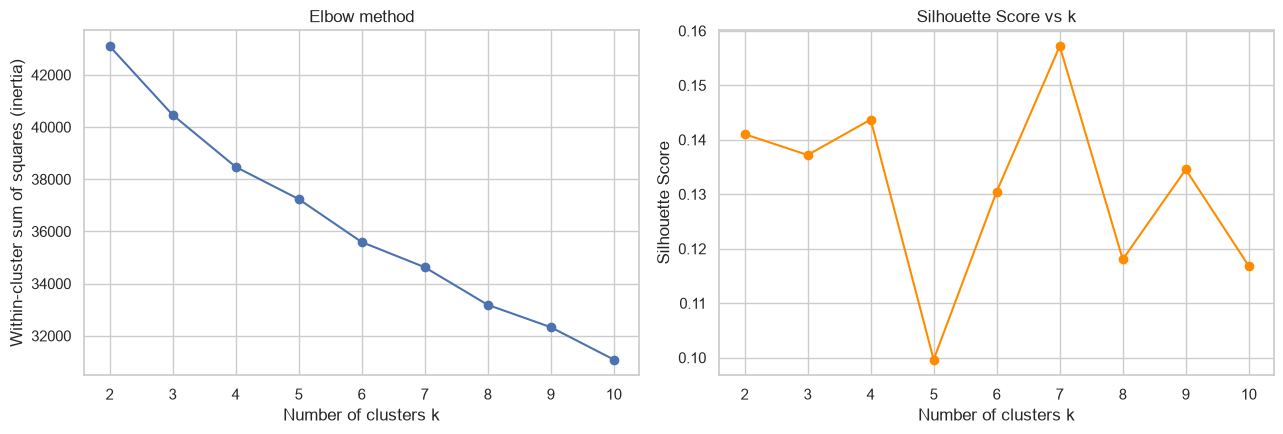

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(kmeans_results_df['k'], kmeans_results_df['inertia'], marker='o')
axes[0].set_xlabel('Number of clusters k')
axes[0].set_ylabel('Within-cluster sum of squares (inertia)')
axes[0].set_title('Elbow method')

axes[1].plot(kmeans_results_df['k'], kmeans_results_df['silhouette'], marker='o', color='darkorange')
axes[1].set_xlabel('Number of clusters k')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score vs k')

plt.tight_layout()
plt.show()

In [15]:
inertia_vals = kmeans_results_df['inertia'].values
k_vals = kmeans_results_df['k'].values

x_norm = (k_vals - k_vals.min()) / (k_vals.max() - k_vals.min())
y_norm = (inertia_vals - inertia_vals.min()) / (inertia_vals.max() - inertia_vals.min())

p1 = np.array([x_norm[0], y_norm[0]])
p2 = np.array([x_norm[-1], y_norm[-1]])
line_vec = p2 - p1
line_vec_norm = line_vec / np.linalg.norm(line_vec)
distances = []
for xi, yi in zip(x_norm, y_norm):
    p = np.array([xi, yi]) - p1
    proj_len = np.dot(p, line_vec_norm)
    proj_point = proj_len * line_vec_norm
    distances.append(np.linalg.norm(p - proj_point))

elbow_k = int(k_vals[np.argmax(distances)])
best_silhouette_k = int(kmeans_results_df.loc[kmeans_results_df['silhouette'].idxmax(), 'k'])

print(f"'Elbow' by maximum distance from the line (elbow method): k={elbow_k}")
print(f"Best k by Silhouette Score: k={best_silhouette_k}")

'Elbow' by maximum distance from the line (elbow method): k=4
Best k by Silhouette Score: k=7


In [23]:
chosen_k = best_silhouette_k
print(f"Selected number of clusters for k-means: k={chosen_k}")

kmeans_final = kmeans_models[chosen_k]
kmeans_labels = kmeans_final.labels_

cluster_sizes = pd.Series(kmeans_labels).value_counts().sort_index()
print(f"Cluster sizes (k={chosen_k}):")
print(cluster_sizes)

Selected number of clusters for k-means: k=7
Cluster sizes (k=7):
0    614
1     22
2    365
3    318
4     58
5     67
6     16
Name: count, dtype: int64


## 7. Evaluation of k-means clustering quality

In [22]:
kmeans_sil = silhouette_score(X_scaled, kmeans_labels)
kmeans_db = davies_bouldin_score(X_scaled, kmeans_labels)
kmeans_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

print(f"k-means (k={chosen_k}) - internal clustering quality metrics:")
print(f"  Silhouette Score:        {kmeans_sil:.4f}")
print(f"  Davies-Bouldin Index:    {kmeans_db:.4f}")
print(f"  Calinski-Harabasz Index: {kmeans_ch:.1f}")

k-means (k=7) - internal clustering quality metrics:
  Silhouette Score:        0.1572
  Davies-Bouldin Index:    1.7579
  Calinski-Harabasz Index: 105.0


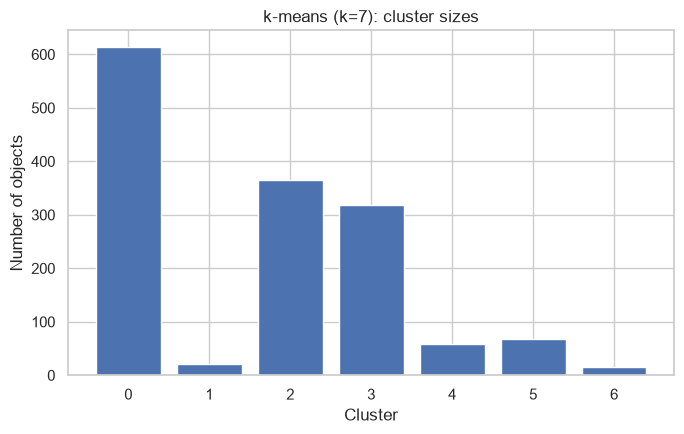

Mean cluster profile (unscaled units):


,OverallQual,GrLivArea,TotalBsmtSF,GarageArea,YearBuilt
cluster,,,,,
0,5.3,1173.5,892.9,398.5,1954.7
1,6.5,1617.5,1150.7,527.7,1977.5
2,7.0,1978.3,963.6,561.9,1988.5
3,7.3,1656.6,1578.4,621.7,1995.7
4,4.9,1796.1,944.5,432.5,1947.3
5,4.6,1016.9,692.2,4.5,1943.0
6,5.7,2203.6,969.6,381.9,1923.8


In [26]:
plt.figure(figsize=(7, 4.5))
plt.bar(cluster_sizes.index.astype(str), cluster_sizes.values, color='#4C72B0')
plt.xlabel('Cluster')
plt.ylabel('Number of objects')
plt.title(f'k-means (k={chosen_k}): cluster sizes')
plt.tight_layout()
plt.show()

profile_cols = [c for c in ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt'] if c in CLUSTER_FEATURES]
cluster_profile = X[profile_cols].copy()
cluster_profile['cluster'] = kmeans_labels
print("Mean cluster profile (unscaled units):")
cluster_profile.groupby('cluster')[profile_cols].mean().round(1)

## 8. DBSCAN

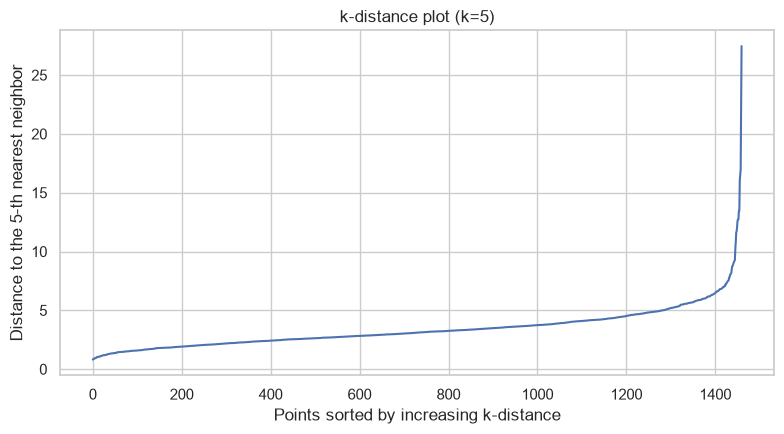

Approximate eps value from the k-distance plot: 6.2


In [32]:
min_samples_for_kdist = 5
nn = NearestNeighbors(n_neighbors=min_samples_for_kdist)
nn.fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4.5))
plt.plot(k_distances)
plt.xlabel('Points sorted by increasing k-distance')
plt.ylabel(f'Distance to the {min_samples_for_kdist}-th nearest neighbor')
plt.title(f'k-distance plot (k={min_samples_for_kdist})')
plt.tight_layout()
plt.show()

x_idx = np.arange(len(k_distances))
x_norm = x_idx /x_idx.max()
y_norm = (k_distances - k_distances.min()) / (k_distances.max() - k_distances.min() + 1e-12)
p1, p2 = np.array([x_norm[0], y_norm[0]]), np.array([x_norm[-1], y_norm[-1]])
line_vec = p2 - p1
line_vec_norm = line_vec / np.linalg.norm(line_vec)
dists = []
for xi, yi in zip(x_norm, y_norm):
    p = np.array([xi, yi]) - p1
    proj = np.dot(p, line_vec_norm) * line_vec_norm
    dists.append(np.linalg.norm(p - proj))
suggested_eps = round(float(k_distances[np.argmax(dists)]), 2)
print(f"Approximate eps value from the k-distance plot: {suggested_eps}")

## 9. Effect of DBSCAN parameters (eps, min_samples)

In [35]:
eps_values =[round(suggested_eps * m, 2) for m in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]]
min_samples_values = [3, 5, 10, 15, 20]

dbscan_grid_results = []
dbscan_models = {}
for eps in eps_values:
    for ms in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=ms)
        labels = model.fit_predict(X_scaled)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = int(np.sum(labels == -1))
        noise_pct = n_noise / len(labels) * 100

        if n_clusters >= 2 and n_noise < len(labels):
            mask = labels != -1
            sil = silhouette_score(X_scaled[mask], labels[mask]) if len(set(labels[mask])) >= 2 else np.nan
        else:
            sil = np.nan 

        dbscan_models[(eps, ms)] = model
        dbscan_grid_results.append({'eps': eps, 'min_samples': ms, 'n_clusters': n_clusters,
                                        'n_noise': n_noise, 'noise_pct': round(noise_pct, 1),
                                        'silhouette_no_noise': sil})

dbscan_grid_df = pd.DataFrame(dbscan_grid_results)
dbscan_grid_df
        

,eps,min_samples,n_clusters,n_noise,noise_pct,silhouette_no_noise
0,3.10,3,14,512,35.1,0.046694
1,3.10,5,5,576,39.5,0.072341
2,3.10,10,3,643,44.0,0.126830
3,3.10,15,3,736,50.4,0.149136
4,3.10,20,2,788,54.0,0.187579
5,4.65,3,5,135,9.2,0.179542
6,4.65,5,2,160,11.0,0.210415
7,4.65,10,2,175,12.0,0.203281
8,4.65,15,2,192,13.2,0.185691
9,4.65,20,2,224,15.3,0.222716


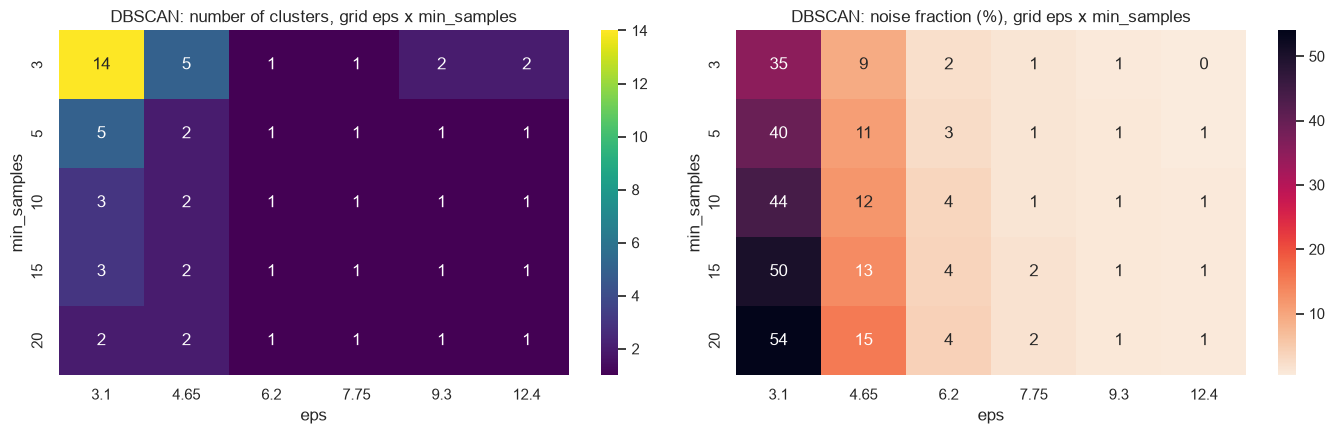

In [36]:
pivot_nclusters = dbscan_grid_df.pivot(index='min_samples', columns='eps', values='n_clusters')
pivot_noise = dbscan_grid_df.pivot(index='min_samples', columns='eps', values='noise_pct')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(pivot_nclusters, annot=True, fmt='.0f', cmap='viridis', ax=axes[0])
axes[0].set_title('DBSCAN: number of clusters, grid eps x min_samples')

sns.heatmap(pivot_noise, annot=True, fmt='.0f', cmap='rocket_r', ax=axes[1])
axes[1].set_title('DBSCAN: noise fraction (%), grid eps x min_samples')

plt.tight_layout()
plt.show()

In [49]:
valid_configs = dbscan_grid_df[(dbscan_grid_df['n_clusters'] >= 2) &
                                      (dbscan_grid_df['n_clusters'] <= 10) &
                                      (dbscan_grid_df['noise_pct'] < 40) &
                                      (dbscan_grid_df['silhouette_no_noise'].notna())]

best_dbscan_row = valid_configs.loc[valid_configs['silhouette_no_noise'].idxmax()]

best_eps = best_dbscan_row['eps']
best_min_samples = int(best_dbscan_row['min_samples'])

print(f"Selected DBSCAN configuration: eps={best_eps}, min_samples={best_min_samples}")
print(f"  Number of clusters: {int(best_dbscan_row['n_clusters'])}")
print(f"  Number of noise objects: {int(best_dbscan_row['n_noise'])} ({best_dbscan_row['noise_pct']:.1f}%)")
print(f"  Silhouette Score (excluding noise): {best_dbscan_row['silhouette_no_noise']:.4f}")

dbscan_final = dbscan_models[(best_eps, best_min_samples)]
dbscan_labels = dbscan_final.labels_

Selected DBSCAN configuration: eps=9.3, min_samples=3
  Number of clusters: 2
  Number of noise objects: 10 (0.7%)
  Silhouette Score (excluding noise): 0.5799


## 10. Evaluation of DBSCAN clustering quality

In [50]:
n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_dbscan = int(np.sum(dbscan_labels == -1))

print(f"DBSCAN (eps={best_eps}, min_samples={best_min_samples}):")
print(f"  Number of clusters: {n_clusters_dbscan}")
print(f"  Number of noise objects: {n_noise_dbscan} of {len(dbscan_labels)} ({n_noise_dbscan/len(dbscan_labels):.1%})")

mask_no_noise = dbscan_labels != -1

dbscan_sil = silhouette_score(X_scaled[mask_no_noise], dbscan_labels[mask_no_noise])
dbscan_db = davies_bouldin_score(X_scaled[mask_no_noise], dbscan_labels[mask_no_noise])
dbscan_ch = calinski_harabasz_score(X_scaled[mask_no_noise], dbscan_labels[mask_no_noise])

print(f"\nInternal quality metrics (computed excluding noise):")
print(f"  Silhouette Score:        {dbscan_sil:.4f}")
print(f"  Davies-Bouldin Index:    {dbscan_db:.4f}")
print(f"  Calinski-Harabasz Index: {dbscan_ch:.1f}")

cluster_sizes_dbscan = pd.Series(dbscan_labels).value_counts().sort_index()
print(f"\nCluster sizes (including noise, label=-1):")
print(cluster_sizes_dbscan)

DBSCAN (eps=9.3, min_samples=3):
  Number of clusters: 2
  Number of noise objects: 10 of 1460 (0.7%)

Internal quality metrics (computed excluding noise):
  Silhouette Score:        0.5799
  Davies-Bouldin Index:    0.5576
  Calinski-Harabasz Index: 26.6

Cluster sizes (including noise, label=-1):
-1      10
 0    1447
 1       3
Name: count, dtype: int64


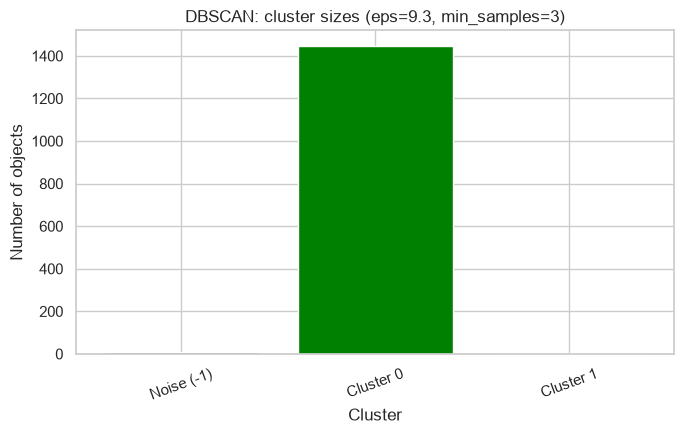

In [51]:
plt.figure(figsize=(7, 4.5))
labels_str = ['Noise (-1)' if i == -1 else f'Cluster {i}' for i in cluster_sizes_dbscan.index]
colors = ['gray' if i == -1 else 'green' for i in cluster_sizes_dbscan.index]
plt.bar(labels_str, cluster_sizes_dbscan.values, color=colors)
plt.xlabel('Cluster')
plt.ylabel('Number of objects')
plt.title(f'DBSCAN: cluster sizes (eps={best_eps}, min_samples={best_min_samples})')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 11. Comparison of k-means and DBSCAN results

In [52]:
comparison_clustering = pd.DataFrame({
    'k-means': {
        'Number of clusters': chosen_k,
        'Silhouette Score': round(kmeans_sil, 4),
        'Davies-Bouldin Index': round(kmeans_db, 4),
        'Calinski-Harabasz Index': round(kmeans_ch, 1),
        'Number of noise objects': 0,
        'Noise fraction, %': 0.0,
    },
    'DBSCAN': {
        'Number of clusters': n_clusters_dbscan,
        'Silhouette Score': round(dbscan_sil, 4) if not np.isnan(dbscan_sil) else 'n/a',
        'Davies-Bouldin Index': round(dbscan_db, 4) if not np.isnan(dbscan_db) else 'n/a',
        'Calinski-Harabasz Index': round(dbscan_ch, 1) if not np.isnan(dbscan_ch) else 'n/a',
        'Number of noise objects': n_noise_dbscan,
        'Noise fraction, %': round(n_noise_dbscan / len(dbscan_labels) * 100, 1),
    },
})

comparison_clustering

,k-means,DBSCAN
Number of clusters,7.0000,2.0000
Silhouette Score,0.1572,0.5799
Davies-Bouldin Index,1.7579,0.5576
Calinski-Harabasz Index,105.0000,26.6000
Number of noise objects,0.0000,10.0000
"Noise fraction, %",0.0000,0.7000


## 12–14. PCA: application, explained variance, choosing the number of components

In [53]:
pca_full = PCA(n_components=len(CLUSTER_FEATURES), random_state=RANDOM_STATE)
pca_full.fit(X_scaled)

explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance_ratio)

pca_variance_df = pd.DataFrame({
    'component': [f'PC{i+1}' for i in range(len(explained_variance_ratio))],
    'explained_variance_ratio': explained_variance_ratio,
    'cumulative_variance': cumulative_variance,
})
pca_variance_df.head(15)

,component,explained_variance_ratio,cumulative_variance
0,PC1,0.204447,0.204447
1,PC2,0.093728,0.298176
2,PC3,0.067394,0.365569
3,PC4,0.059404,0.424973
4,PC5,0.045369,0.470342
5,PC6,0.037718,0.508060
6,PC7,0.033704,0.541764
7,PC8,0.032864,0.574627
8,PC9,0.031875,0.606502
9,PC10,0.031563,0.638066


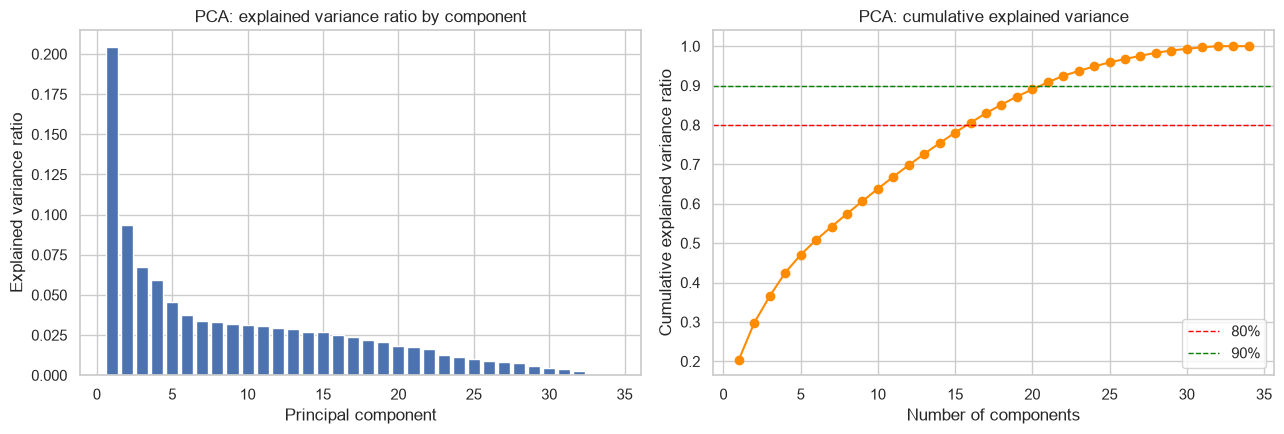

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio)
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('Explained variance ratio')
axes[0].set_title('PCA: explained variance ratio by component')

axes[1].plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', color='darkorange')
axes[1].axhline(0.8, color='red', linestyle='--', linewidth=1, label='80%')
axes[1].axhline(0.9, color='green', linestyle='--', linewidth=1, label='90%')
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('Cumulative explained variance ratio')
axes[1].set_title('PCA: cumulative explained variance')
axes[1].legend()

plt.tight_layout()
plt.show()


In [58]:
n_components_80 = int(np.argmax(cumulative_variance >= 0.80) + 1)
n_components_90 = int(np.argmax(cumulative_variance >= 0.90) + 1)

print(f"Number of components to retain >=80% of variance: {n_components_80} "
      f"(accumulated {cumulative_variance[n_components_80-1]:.1%})")
print(f"Number of components to retain >=90% of variance: {n_components_90} "
      f"(accumulated {cumulative_variance[n_components_90-1]:.1%})")

Number of components to retain >=80% of variance: 16 (accumulated 80.6%)
Number of components to retain >=90% of variance: 21 (accumulated 90.8%)


## 15. Reducing the data to two principal components

In [59]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_scaled)

pca_2d_df = pd.DataFrame(X_pca_2d, columns=['PC1', 'PC2'])

explained_2d = pca_2d.explained_variance_ratio_
print(f"Explained variance ratio of PC1: {explained_2d[0]:.1%}")
print(f"Explained variance ratio of PC2: {explained_2d[1]:.1%}")
print(f"Total (PC1+PC2): {explained_2d.sum():.1%}")

pca_2d_df.head()

Explained variance ratio of PC1: 20.4%
Explained variance ratio of PC2: 9.4%
Total (PC1+PC2): 29.8%


,PC1,PC2
0,1.291820,0.669979
1,0.070709,-1.261373
2,1.454551,0.422727
3,-0.404768,0.934514
4,4.277063,1.098084


In [60]:
loadings = pd.DataFrame(pca_2d.components_.T, columns=['PC1', 'PC2'], index=CLUSTER_FEATURES)
top_contrib_pc1 = loadings['PC1'].abs().sort_values(ascending=False).head(8)
top_contrib_pc2 = loadings['PC2'].abs().sort_values(ascending=False).head(8)

print("Features with the largest contribution to PC1:")
display(loadings.loc[top_contrib_pc1.index, ['PC1']])
print("\nFeatures with the largest contribution to PC2:")
display(loadings.loc[top_contrib_pc2.index, ['PC2']])

Features with the largest contribution to PC1:


,PC1
GrLivArea,0.309685
OverallQual,0.301833
GarageCars,0.291191
GarageArea,0.286767
1stFlrSF,0.265035
TotalBsmtSF,0.263557
FullBath,0.258755
TotRmsAbvGrd,0.249996



Features with the largest contribution to PC2:


,PC2
2ndFlrSF,0.431403
BedroomAbvGr,0.346164
TotRmsAbvGrd,0.312988
BsmtFinSF1,-0.309743
BsmtFullBath,-0.298689
GrLivArea,0.236332
HalfBath,0.231026
TotalBsmtSF,-0.229191


## 16. Visualization of clustering results in PCA space

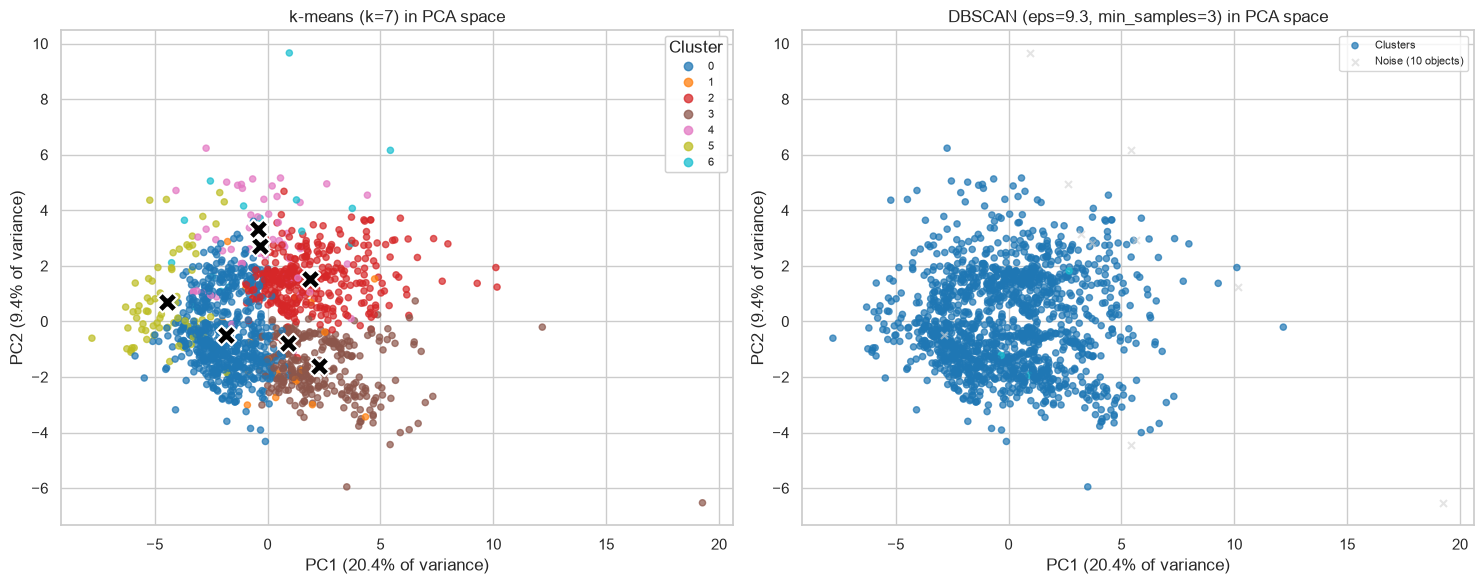

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

scatter1 = axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=kmeans_labels, cmap='tab10', s=20, alpha=0.7)
centroids_pca = pca_2d.transform(kmeans_final.cluster_centers_)
axes[0].scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='black', marker='X', s=200,
                edgecolors='white', linewidths=1.5, label='Centroids')
axes[0].set_xlabel(f'PC1 ({explained_2d[0]:.1%} of variance)')
axes[0].set_ylabel(f'PC2 ({explained_2d[1]:.1%} of variance)')
axes[0].set_title(f'k-means (k={chosen_k}) in PCA space')
axes[0].legend()
legend1 = axes[0].legend(*scatter1.legend_elements(), title="Cluster", loc='upper right', fontsize=8)
axes[0].add_artist(legend1)


noise_mask = dbscan_labels == -1
non_noise_mask = ~noise_mask

scatter2 = axes[1].scatter(X_pca_2d[non_noise_mask, 0], X_pca_2d[non_noise_mask, 1],
                            c=dbscan_labels[non_noise_mask], cmap='tab10', s=20, alpha=0.7, label='Clusters')
axes[1].scatter(X_pca_2d[noise_mask, 0], X_pca_2d[noise_mask, 1],
                 c='lightgray', marker='x', s=25, alpha=0.6, label=f'Noise ({noise_mask.sum()} objects)')
axes[1].set_xlabel(f'PC1 ({explained_2d[0]:.1%} of variance)')
axes[1].set_ylabel(f'PC2 ({explained_2d[1]:.1%} of variance)')
axes[1].set_title(f'DBSCAN (eps={best_eps}, min_samples={best_min_samples}) in PCA space')
axes[1].legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

## 17. Analysis of visualizations: separation, overlap, compactness, noise/anomalies

In [63]:
centroid_distances = squareform(pdist(centroids_pca))
np.fill_diagonal(centroid_distances, np.nan)
print("Distances between k-means cluster centroids in PCA space:")
display(pd.DataFrame(centroid_distances, index=[f'C{i}' for i in range(chosen_k)],
                      columns=[f'C{i}' for i in range(chosen_k)]).round(2))

min_centroid_dist = np.nanmin(centroid_distances)
print(f"\nMinimum distance between centroids: {min_centroid_dist:.2f}")

Distances between k-means cluster centroids in PCA space:


,C0,C1,C2,C3,C4,C5,C6
C0,NaN,2.75,4.22,4.26,3.51,2.87,4.05
C1,2.75,NaN,2.50,1.60,3.70,5.56,4.33
C2,4.22,2.50,NaN,3.13,2.52,6.39,2.95
C3,4.26,1.60,3.13,NaN,5.03,7.11,5.62
C4,3.51,3.70,2.52,5.03,NaN,4.57,0.63
C5,2.87,5.56,6.39,7.11,4.57,NaN,4.80
C6,4.05,4.33,2.95,5.62,0.63,4.80,NaN



Minimum distance between centroids: 0.63


## 18. Comparison of the original feature space and the representation after PCA

In [66]:
print(f"Original dimensionality of the feature space: {X_scaled.shape[1]}")
print(f"Dimensionality after reduction to 2D: 2")
print(f"Share of information retained (explained variance) in 2D: {explained_2d.sum():.1%}")
print(f"Share of information lost in 2D: {1 - explained_2d.sum():.1%}")

Original dimensionality of the feature space: 34
Dimensionality after reduction to 2D: 2
Share of information retained (explained variance) in 2D: 29.8%
Share of information lost in 2D: 70.2%


In [68]:
kmeans_2d = KMeans(n_clusters=chosen_k, random_state=RANDOM_STATE, n_init=10)
labels_2d = kmeans_2d.fit_predict(X_pca_2d)
sil_2d = silhouette_score(X_pca_2d, labels_2d)

print(f"Silhouette Score of k-means in the original space ({X_scaled.shape[1]} features): {kmeans_sil:.4f}")
print(f"Silhouette Score of k-means in the 2D PCA space: {sil_2d:.4f}")
print(f"\nLabel consistency (Adjusted Rand Index) between clustering in the original "
      "space and in the 2D PCA space:")
ari = adjusted_rand_score(kmeans_labels, labels_2d)
print(f"  ARI = {ari:.4f}  (1.0 = identical labels, 0.0 = random agreement)")

Silhouette Score of k-means in the original space (34 features): 0.1572
Silhouette Score of k-means in the 2D PCA space: 0.3600

Label consistency (Adjusted Rand Index) between clustering in the original space and in the 2D PCA space:
  ARI = 0.3838  (1.0 = identical labels, 0.0 = random agreement)
